# Step 2 – Landscape of quantum computing 

How concentrated is the production of quantum computing inventions, is it consolidating, and how does it differ by type of applicant and by country? 


- **Data**: the families of Step 0 (`qc_applicants_PROD.csv`) and the actors of the Step 2 harmonisation (`org_groups.csv`, column `group_final`).
- **Unit**: the DOCDB family, dated by its earliest filing year, 2010–2023. From 2021 on the years are shaded grey in the plots: they may still be incomplete because of the publication lag.
- **Actors**: organisations only, as in the harmonisation. Individuals are not harmonised, so they appear only in the description by type (Section 1).
- **Counting**: full counting, as in notebook 11: a family with two actors counts once for each of them.

| Section | Question |
|---|---|
| 1 | Who patents: companies, universities, government / non-profit, individuals? |
| 2 | How concentrated is the whole field? |
| 3 | Is it consolidating over time? |
| 4 | How does concentration differ across countries? |

## 0. Setup

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # Lotka regression and Kendall's tau

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == "Group15_innovation")
APPLICANTS_FILE = ROOT / "outputs" / "step2_input" / "qc_applicants_PROD.csv"   # Step 0: one row per family-applicant
GROUPS_FILE = ROOT / "step2_validation" / "org_groups.csv"                     # Step 2 harmonisation: final group of each row
OUTPUT_DIR = ROOT / "outputs" / "step2" / "concentration"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

YEAR_MIN, YEAR_MAX = 2010, 2023      # earliest filing year of the family
GREY_FROM = 2021                     # years shaded grey: possibly incomplete
SPLIT_YEAR = 2015                    # start of the growth phase (Step 2 split year)
WINDOW = 3                           # years per window (notebook 11)
TOP_N = 5                            # actors listed per type / window
N_COUNTRIES = 10                     # countries compared in Section 4
TYPES = ["company", "university", "gov / non-profit"]

### 0.1 Metric functions

Copied from notebook 11 (Section 3). Each function takes `patents_per_firm`, the number of families of each actor.

In [2]:
def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def six_measures(patents_per_firm):
    "All the measures for one group of firms, as one row of a table."
    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }


def shade(ax, split=True):
    "Grey band on the possibly incomplete years, dashed line at the split year."
    ax.axvspan(GREY_FROM - 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.2, label=f"{GREY_FROM}+ possibly incomplete")
    if split:
        ax.axvline(SPLIT_YEAR - 0.5, color="black", ls="--", lw=1, label=f"split ({SPLIT_YEAR})")

ORG_LABELS = {"firms": "organisations", "patents (sum over firms)": "families (sum over organisations)"}

### 0.2 Applicant types

Same rules as `step2_harmonization` (Section 1), copied here so that the types are identical: PATSTAT `psn_sector` when known, otherwise rules on the name. Government and non-profit stay in one type, because PATSTAT has a single `GOV NON-PROFIT` sector.

In [3]:
LEGAL = ["INC", "LLC", "LLLP", "LL", "LTD", "LIMITED", "CORP", "CORPORATION", "CO", "COMPANY", "COPMANY", "GMBH", "AG", "SE",
         "SA", "SAS", "SARL", "SRL", "SPA", "SL", "BV", "NV", "NA", "OY", "AB", "AS", "ASA", "PTY", "PLC", "KK", "LLP", "LP",
         "PTE", "KG", "OOO", "SP Z OO", "SPOLKA", "JOINT.STOCK", "ANONIM SIRKETI", "OBSHCHESTVO"]
LEGAL_CJK = ["有限公司", "株式会社", "股份", "公司", "会社", "주식회사", "インコーポレイテッド", "アクチボラグ"]
UNIV = ["UNIV", "COLLEGE", "POLYTECHN", "POLITECNIC", "ECOLE", "HOCHSCHULE", "SCHOOL", "INSTITUTE OF TECHNOLOGY", "GIJUKU",
        "TRUSTEES", "EDUCATIONAL FUND", "大学", "大學", "学院", "カレッジ", "義塾", r"\bETH\b", r"\bEPFL\b", r"\bUESTC\b"]
GOV = ["INSTIT", "INSTYTUT", "INSTUTUC", "ИНСТИТУТ", "ACADEM", "COMMISSARIAT", "CNRS", "LABORATORY", "CENTER", "CENTRE",
       "CENTRUM", "ZENTRUM", "FOUNDATION", "FONDAZIONE", "FUNDACIO", "STIFTUNG", "FRAUNHOFER", "FROUNHAV", "PLANCK",
       "GOVERNMENT", "MINISTRY", "MINISTERIUM", "BUNDES", "FEDERATSIYA", "AGENTSTVO", "UCHREZHDENIE", "SECRETARY", "AGENCY",
       "COUNCIL", "CONSEJO", "CONSIGLIO", r"\bNATIONAL\b", "IDRYMA", "ASSOCIATION", "HOSPITAL", "ARMY", "AIR FORCE", "NAVY",
       "RIKEN", r"\bTNO\b", "NASA", "研究", "中心", "委员会", "科学院", "センター"]
FIRM = ["TECHNOLOG", "QUANT", "COMPUT", "SYSTEM", "SOLUTION", r"\bLABS?\b", "SOFTWARE", "NETWORK", "ELECTRONIC", "SEMICONDUCT",
        "PHOTONIC", "DEVICES", "INDUSTR", "HOLDING", "GROUP", "CAPITAL", "VENTURES", "ENTERPRISE", "INTERNATIONAL", "SCIENCE",
        "DIGITAL", "DATA", "INTELLIGEN", "ENERGY", "PHARMA", "SECUR", "MACHINES", "INSTRUMENTS", "ENGINEERING", "INNOVATION",
        "BLOCKCHAIN", "BANK", "INSURANCE", "PORTFOLIO", r"\bAI\b", "&", r"\+", "科技", "技术", "量子"]

LEGAL_RE = re.compile(r"\b(" + "|".join(LEGAL) + r")\b|" + "|".join(LEGAL_CJK))
UNIV_RE, GOV_RE, FIRM_RE = (re.compile("|".join(words)) for words in (UNIV, GOV, FIRM))
WORD = r"[^\W\d_]+(?:['\-][^\W\d_]+)*"                              # letters only, any alphabet; O'NEIL, JEAN-PAUL
PERSON_COMMA = re.compile(rf"^{WORD}( {WORD}){{0,3}} ?, ?{WORD}")     # 'SURNAME, Name', 'VAN LAER, Raphael'
PERSON_WORDS = re.compile(rf"^{WORD}( {WORD}){{1,3}}$")               # 'LESCANNE Raphael', 'Taylor Lee Patti'


def normalise(name):
    "Upper case, no accents, full-width characters -> ASCII, no dots, no '?' (characters lost in PATSTAT)."
    s = unicodedata.normalize("NFKC", str(name))
    s = "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c)).upper()
    s = " ".join(s.replace("?", "").replace(".", "").split())
    return s.replace("UNIVERSITY CORPORATION", "UNIVERSITY")             # Japanese national universities


def type_from_name(name):
    n = normalise(name)
    if LEGAL_RE.search(n): return "company"
    if UNIV_RE.search(n):  return "university"
    if GOV_RE.search(n):   return "gov / non-profit"
    if FIRM_RE.search(n):  return "company"
    if PERSON_COMMA.match(n) or PERSON_WORDS.match(n) or "·" in n:   # '·' separates names in Chinese transliterations
        return "individual"
    if len(n.split()) == 1: return "company"
    return "uncertain"


def type_from_patstat(sector):
    s = str(sector).upper()
    if "UNIVERSITY" in s:             return "university"
    if "GOV" in s or "HOSPITAL" in s: return "gov / non-profit"
    if "COMPANY" in s:                return "company"
    if "INDIVIDUAL" in s:             return "individual"
    return None                                                        # UNKNOWN or empty

In [4]:
df = pd.read_csv(APPLICANTS_FILE)

# one type per psn_id, plus the three uncertain names set by hand in the harmonisation
person = df.groupby("psn_id").agg(psn_name=("psn_name", "first"), psn_sector=("psn_sector", "first"))
person["type"] = person["psn_sector"].map(type_from_patstat)
by_name = person["type"].isna()
person.loc[by_name, "type"] = person.loc[by_name, "psn_name"].map(type_from_name)
person.loc[[6733642, 187402713], "type"] = "company"        # DHITECH, PEARL COHEN
person.loc[7821231, "type"] = "gov / non-profit"           # INSERM, transliterated
df["type"] = df["psn_id"].map(person["type"])
df = df[df["psn_name"] != "-NOT AVAILABLE-"]

### 0.3 Actors

Each actor gets **one type** (the type with most families: it matters for 12 mixed groups, e.g. UCAS inside the Chinese Academy of Sciences) and **one country**, assigned in three steps:

1. the most frequent known applicant country among its families (rule of notebook 11, applied to all the psn_id of the group);
2. if none, the script of its names (hangul → KR, kana → JP, Chinese characters → CN);
3. if none, the most frequent office of first filing of its families (EP and WO excluded: they are not countries).

In [5]:
groups = pd.read_csv(GROUPS_FILE, encoding="utf-8-sig")
org = df[df["type"] != "individual"].reset_index(drop=True)
assert (org["psn_id"].to_numpy() == groups["psn_id"].to_numpy()).all(), "org_groups.csv is not aligned"
org["actor"] = groups["group_final"].to_numpy()
fam_actor = org.drop_duplicates(["docdb_family_id", "actor"])           # one row per family and actor


def most_frequent(values):
    return values.value_counts().index[0]


def script_country(names):
    s = "".join(names)
    if re.search(r"[\uac00-\ud7af]", s): return "KR"     # hangul
    if re.search(r"[\u3040-\u30ff]", s): return "JP"     # hiragana / katakana
    if re.search(r"[\u4e00-\u9fff]", s): return "CN"     # Chinese characters only
    return None


# country: first rule that gives a value
known = org.assign(ctry=org["applicant_ctry"].str.strip().replace("", np.nan)).dropna(subset=["ctry"])
rules = {
    "1 applicant country": known.drop_duplicates(["docdb_family_id", "actor", "ctry"]).groupby("actor")["ctry"].agg(most_frequent),
    "2 script of the name": org.groupby("actor")["psn_name"].agg(lambda s: script_country(s.unique())),
    "3 first filing office": fam_actor[~fam_actor["first_office"].isin(["EP", "WO"])].groupby("actor")["first_office"].agg(most_frequent),
}
actors = pd.DataFrame({"type": fam_actor.groupby("actor")["type"].agg(most_frequent),   # type with most families
                       "country": None, "country rule": "none"})
for rule, values in rules.items():
    todo = actors.index[actors["country"].isna() & actors.index.isin(values.dropna().index)]
    actors.loc[todo, ["country", "country rule"]] = list(zip(values[todo], [rule] * len(todo)))

# links used by all the measures: one row per family and actor, in the period
links = (fam_actor.rename(columns={"docdb_family_id": "family", "family_year": "year"})
         .query("@YEAR_MIN <= year <= @YEAR_MAX")[["family", "actor", "year"]]
         .join(actors[["type", "country"]], on="actor"))
actors["families"] = links.groupby("actor")["family"].nunique()
actors = actors.dropna(subset=["families"]).astype({"families": int}).sort_values("families", ascending=False)
actors.to_csv(OUTPUT_DIR / "actors.csv", encoding="utf-8-sig")
print(f"{links['family'].nunique():,} families {YEAR_MIN}-{YEAR_MAX} - organisation "
      f"| {len(actors):,} actors | {len(links):,} family-actor links")
rule_table = actors.groupby("country rule").agg(actors=("type", "size"), families=("families", "sum"))
rule_table["share of links (%)"] = (rule_table["families"] / rule_table["families"].sum() * 100).round(1)
display(rule_table)

11,539 families 2010-2023 - organisation | 2,226 actors | 13,160 family-actor links


,actors,families,share of links (%)
country rule,,,
1 applicant country,1249,10523,80.0
2 script of the name,14,21,0.2
3 first filing office,937,2586,19.7
none,26,30,0.2


## 1. Who patents? Applicant types

A family is counted **once in every type** it has (a family of a company and a university counts for both), so the shares sum to more than 100%. Individuals are counted by psn_id, because they are not harmonised.

families with at least one applicant: 11,886


,actors,families with at least one,share of families (%),families with this type only
type,,,,
company,"1,370","8,490",71.4,"7,725"
university,654,"2,863",24.1,"2,283"
gov / non-profit,202,784,6.6,531
individual,"1,610",819,6.9,347


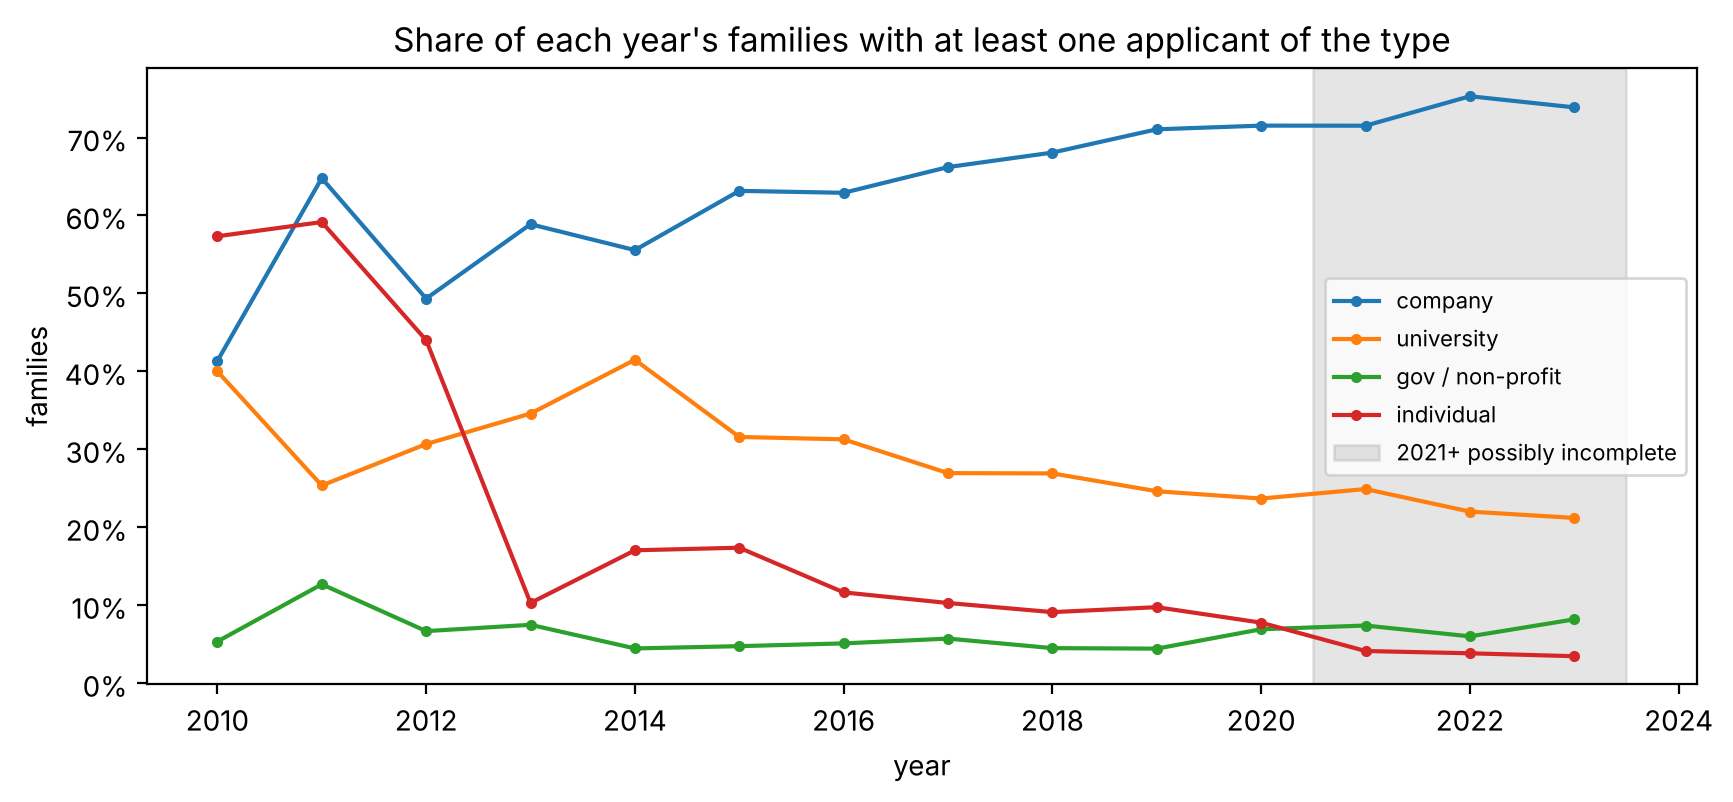

In [6]:
persons = df[(df["type"] == "individual") & df["family_year"].between(YEAR_MIN, YEAR_MAX)]
typed = pd.concat([links[["family", "year", "type"]],
                   persons.rename(columns={"docdb_family_id": "family", "family_year": "year"})[["family", "year", "type"]]]
                  ).drop_duplicates()
n_families = typed["family"].nunique()

ONLY = "families with this type only"
by_type = pd.DataFrame({
    "actors": pd.concat([actors["type"], persons.drop_duplicates("psn_id")["type"]]).value_counts(),
    "families with at least one": typed.groupby("type")["family"].nunique(),
    ONLY: typed.groupby("family")["type"].agg(set).loc[lambda s: s.str.len() == 1].str.join("").value_counts(),
}).reindex(TYPES + ["individual"])
by_type.insert(2, "share of families (%)", by_type["families with at least one"] / n_families * 100)   # ONLY stays last
print(f"families with at least one applicant: {n_families:,}")
display(by_type.style.format("{:,.0f}").format("{:.1f}", subset=["share of families (%)"])
        .set_properties(subset=[ONLY], **{"background-color": "#e8eef7"}))

share_year = (typed.groupby(["year", "type"])["family"].nunique().unstack()
              .div(typed.groupby("year")["family"].nunique(), axis=0) * 100)[TYPES + ["individual"]]
fig, ax = plt.subplots(figsize=(10, 4))
share_year.plot(ax=ax, marker="o", ms=3)
shade(ax, split=False)
ax.set(title="Share of each year's families with at least one applicant of the type", xlabel="year", ylabel="families")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(fontsize=8)
plt.show()

**From here on, organisations only.** Individuals are left out of co-ownership and of all the concentration measures in the rest of the notebook, for three reasons:

- they are not harmonised: one person can have several psn_id, and different people share common names, so their counts are not reliable;
- until the America Invents Act (2012) US inventors were applicants by law, so many of them are inventors, not owners (see their fall in the plot above);
- the question is who controls the production of the technology, i.e. organisational ownership, as in the harmonisation.

The cost is small: 347 families (2.9%) have only individuals as applicants and drop out; the other 472 families with an individual stay, counted through their organisations. The base of the measures is therefore 11,539 families.

**Co-ownership between types.** Families of organisations with two or more types of actor.

In [7]:
mix = links.groupby("family")["type"].agg(lambda s: " + ".join(sorted(set(s))))
mix = mix[mix.str.contains(r"\+")].value_counts().rename("families").to_frame()
mix.loc["total co-owned"] = mix["families"].sum()
mix["share of all families (%)"] = mix["families"] / links["family"].nunique() * 100
display(mix.round(1))

,families,share of all families (%)
type,,
company + university,325,2.8
gov / non-profit + university,137,1.2
company + gov / non-profit,74,0.6
company + gov / non-profit + university,31,0.3
total co-owned,567,4.9


**Results.** Companies are on 71% of the families, universities on 24%, government / non-profit and individuals on about 7% each; 347 families have only individuals and are left out of the measures. Individuals fall from about 60% of the families in 2010–11 to 10% or less from 2017, after the America Invents Act (2012) stopped US inventors from being applicants by law; companies rise from 41% to over 70%. Co-ownership between types is rare (5% of the families, mostly company + university).

## 2. How concentrated is the whole field?

The six measures on all the organisations, 2010–2023.

In [8]:
families_per_actor = links.groupby("actor")["family"].nunique()     # families of each actor, 2010-2023
x_all = families_per_actor.to_numpy()
overall = pd.Series(six_measures(x_all), name=f"{YEAR_MIN}-{YEAR_MAX}")
display(overall.rename(ORG_LABELS).round(3).to_frame())

,2010-2023
organisations,2226.000
families (sum over organisations),13160.000
CV,5.495
CR4 (%),18.746
CR8 (%),24.764
HH,0.014
1/HH,71.394
Lotka L,-1.074
Lotka p-value,0.000
Gini,0.744


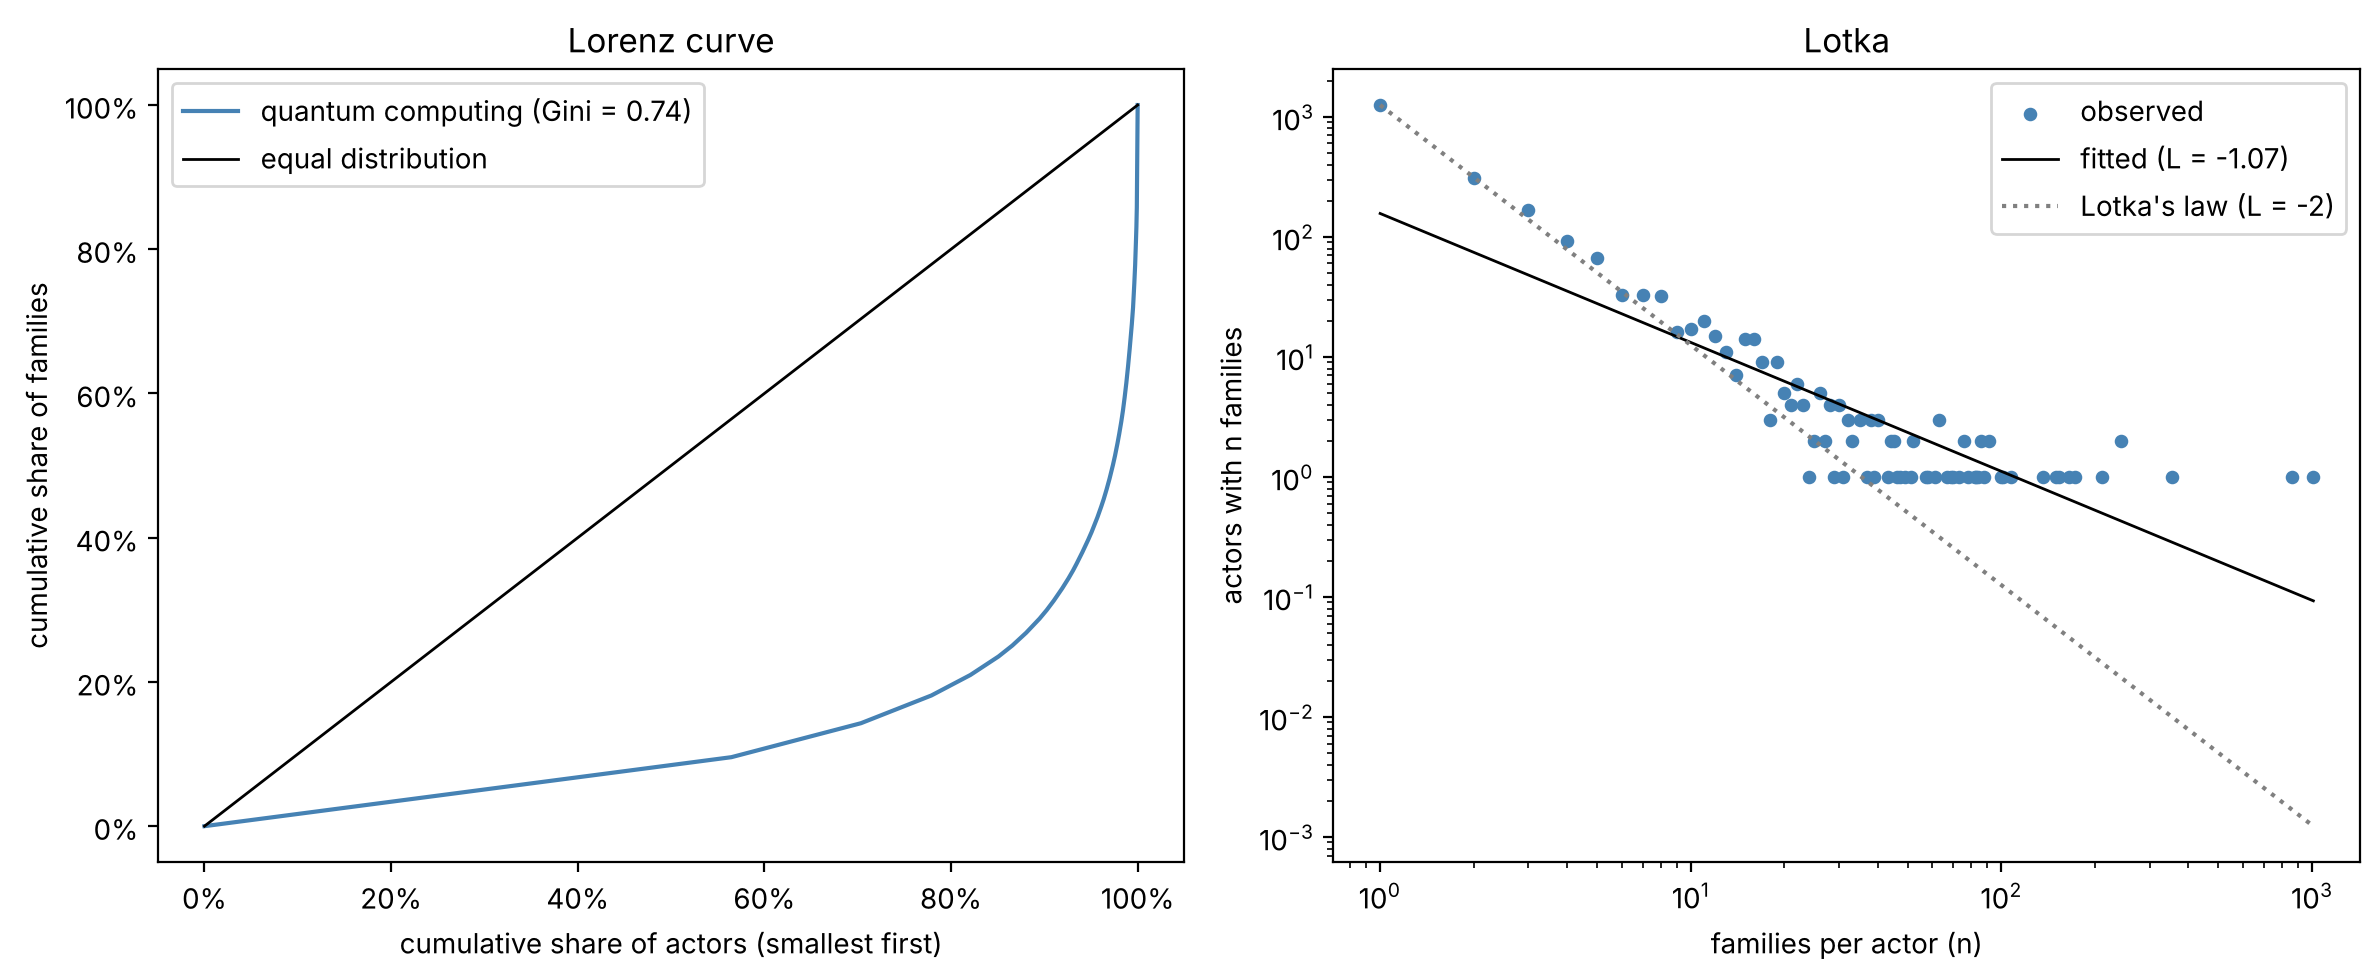

families per actor (n),1,2,3,4,5,6,7,8
actors observed,1255.0,309.0,168.0,93.0,67.0,33.0,33.0,32.0
actors predicted (f(1)/n²),1255.0,313.8,139.4,78.4,50.2,34.9,25.6,19.6


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Lorenz curve
share_of_firms, share_of_patents = lorenz_curve(x_all)
axes[0].plot(share_of_firms, share_of_patents, color="steelblue", label=f"quantum computing (Gini = {gini(x_all):.2f})")
axes[0].plot([0, 1], [0, 1], color="black", lw=1, label="equal distribution")
axes[0].set(title="Lorenz curve", xlabel="cumulative share of actors (smallest first)", ylabel="cumulative share of families")
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend()

# Lotka: number of actors with n families, log-log
L = overall["Lotka L"]
observed = pd.Series(x_all).value_counts().sort_index()
n = observed.index.to_numpy()
axes[1].scatter(n, observed.values, color="steelblue", s=15, label="observed")
axes[1].plot(n, np.exp(np.log(observed.values).mean() - L * np.log(n).mean()) * n ** L,
             color="black", lw=1, label=f"fitted (L = {L:.2f})")
axes[1].plot(n, observed[1] / n ** 2, color="grey", ls=":", label="Lotka's law (L = -2)")
axes[1].set(xscale="log", yscale="log", title="Lotka", xlabel="families per actor (n)", ylabel="actors with n families")
axes[1].legend()
plt.tight_layout()
plt.show()

lotka_check = pd.DataFrame({"actors observed": observed, "actors predicted (f(1)/n²)": observed[1] / n ** 2})
lotka_check.index.name = "families per actor (n)"
display(lotka_check.head(8).round(1).T)

**Results** (2,226 organisations, 13,160 family-actor links).

- **CR4 = 18.7%, CR8 = 24.8%**: share of the links held by the 4 and 8 largest actors. Origin Quantum, IBM, Baidu and Google hold almost one link in five. The next four add only 6 points (Microsoft, Fujitsu, IonQ, and Intel), so the head is made of very few actors. Microsoft has the same number of families as Google (243): which of the two is fourth is a tie, and CR4 does not change.
- **HH = 0.014, 1/HH = 71**: sum of the squared shares, and the number of equal-sized actors that would give the same HH. The field behaves like 71 equal actors instead of 2,226: low concentration in absolute terms.
- **CV = 5.5**: standard deviation over the mean of families per actor. The spread is 5.5 times the mean: the actors are very different in size.
- **Gini = 0.74** (Lorenz curve): 0 = all actors equal, 1 = one actor has everything. Few big actors.
- **Lotka L = −1.07** (p < 0.001): slope of log(actors with *n* families) on log(*n*). Lotka's law predicts −2; a slope closer to 0 means that the number of actors falls more slowly as *n* grows, i.e. more large actors than expected. The table shows it from *n* = 3 on (e.g. 32 actors with 8 families against 20 predicted), and in the plot the largest actors lie far above the dotted line.

**Reading.** Low HH and CR4 but high Gini, CV and Lotka are not a contradiction: they measure different things. The field is **not dominated** by one or a few actors, but it is **very unequal**: a small group of large patentees and a long tail of actors with one or two families.

**Concentration inside each type.** The six measures computed on the actors of each type, as the paper does for countries.

In [10]:
families_per_actor = links.groupby("actor")["family"].nunique()
table_types = pd.DataFrame({t: six_measures(families_per_actor[actors.index[actors["type"] == t]].to_numpy())
                            for t in TYPES}).T
table_types.loc["all organisations"] = six_measures(families_per_actor.to_numpy())
display(table_types.rename(columns=ORG_LABELS).round(3))

top_by_type = pd.concat({t: actors[actors["type"] == t].head(TOP_N)[["country", "families"]] for t in TYPES})
display(top_by_type)

,organisations,families (sum over organisations),CV,CR4 (%),CR8 (%),HH,1/HH,Lotka L,Lotka p-value,Gini
company,1370.0,9144.0,6.096,26.979,35.641,0.028,35.925,-0.893,0.0,0.786
university,654.0,3147.0,2.027,11.598,17.477,0.008,128.134,-1.285,0.0,0.642
gov / non-profit,202.0,869.0,2.157,28.078,39.701,0.028,35.876,-1.070,0.0,0.639
all organisations,2226.0,13160.0,5.495,18.746,24.764,0.014,71.394,-1.074,0.0,0.744


country  \
                 actor                                                   
company          ORIGIN QUANTUM                                     CN   
                 IBM                                                US   
                 BAIDU                                              CN   
                 GOOGLE (ALPHABET)                                  US   
                 MICROSOFT                                          US   
university       TSINGHUA UNIV                                      CN   
                 MIT                                                US   
                 USTC                                               CN   
                 CHINESE ACADEMY OF SCIENCES                        CN   
                 HARVARD UNIV                                       US   
gov / non-profit ETRI                                               KR   
                 CEA                                                FR   
                 YANGTZE RIVER DELTA QUANTUM INNOVATION CENTER      CN   
                 CNRS                                               FR   
                 RIKEN                                              JP   

                                                                families  
                 actor                                                    
company          ORIGIN QUANTUM                                     1010  
                 IBM                                                 860  
                 BAIDU                                               354  
                 GOOGLE (ALPHABET)                                   243  
                 MICROSOFT                                           243  
university       TSINGHUA UNIV                                       100  
                 MIT                                                  91  
                 USTC                                                 88  
                 CHINESE ACADEMY OF SCIENCES                          86  
                 HARVARD UNIV                                         49  
gov / non-profit ETRI                                                 69  
                 CEA                                                  67  
                 YANGTZE RIVER DELTA QUANTUM INNOVATION CENTER        57  
                 CNRS                                                 51  
                 RIKEN                                                30

**Results.** Companies are by far the most concentrated type (CR4 27%, Gini 0.79), because of a few giants (Origin Quantum, IBM, Baidu); universities are the most dispersed (CR4 12%, 1/HH = 128). Government / non-profit has a high CR4 (28%) but only 202 actors.

## 3. Is the field consolidating?

The field is consolidating if fewer actors hold more of the families over time: CR4, CR8 and HH rising, 1/HH falling. First the measures year by year, then on windows of 3 years (single early years are small: about 60–130 families a year before 2015).

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
families,63.000,65.000,63.000,98.000,127.000,178.000,260.000,414.000,705.000,1063.000,1373.000,1861.000,2448.000,2821.000
organisations,46.000,49.000,46.000,61.000,92.000,103.000,134.000,193.000,300.000,423.000,511.000,676.000,739.000,849.000
CR4 (%),31.429,26.316,31.944,36.975,16.667,23.077,29.831,27.412,22.893,25.520,18.204,21.826,22.307,20.626
CR8 (%),44.286,40.789,43.056,48.739,27.333,36.058,40.678,37.719,31.447,32.918,24.830,27.386,28.639,26.448
HH,0.038,0.033,0.040,0.047,0.017,0.025,0.032,0.027,0.024,0.024,0.015,0.020,0.019,0.017
1/HH,26.630,30.400,24.923,21.295,57.990,40.134,30.849,37.158,41.447,41.751,66.718,49.988,51.672,58.200
Gini,0.299,0.298,0.311,0.427,0.308,0.433,0.476,0.510,0.541,0.575,0.580,0.598,0.633,0.636


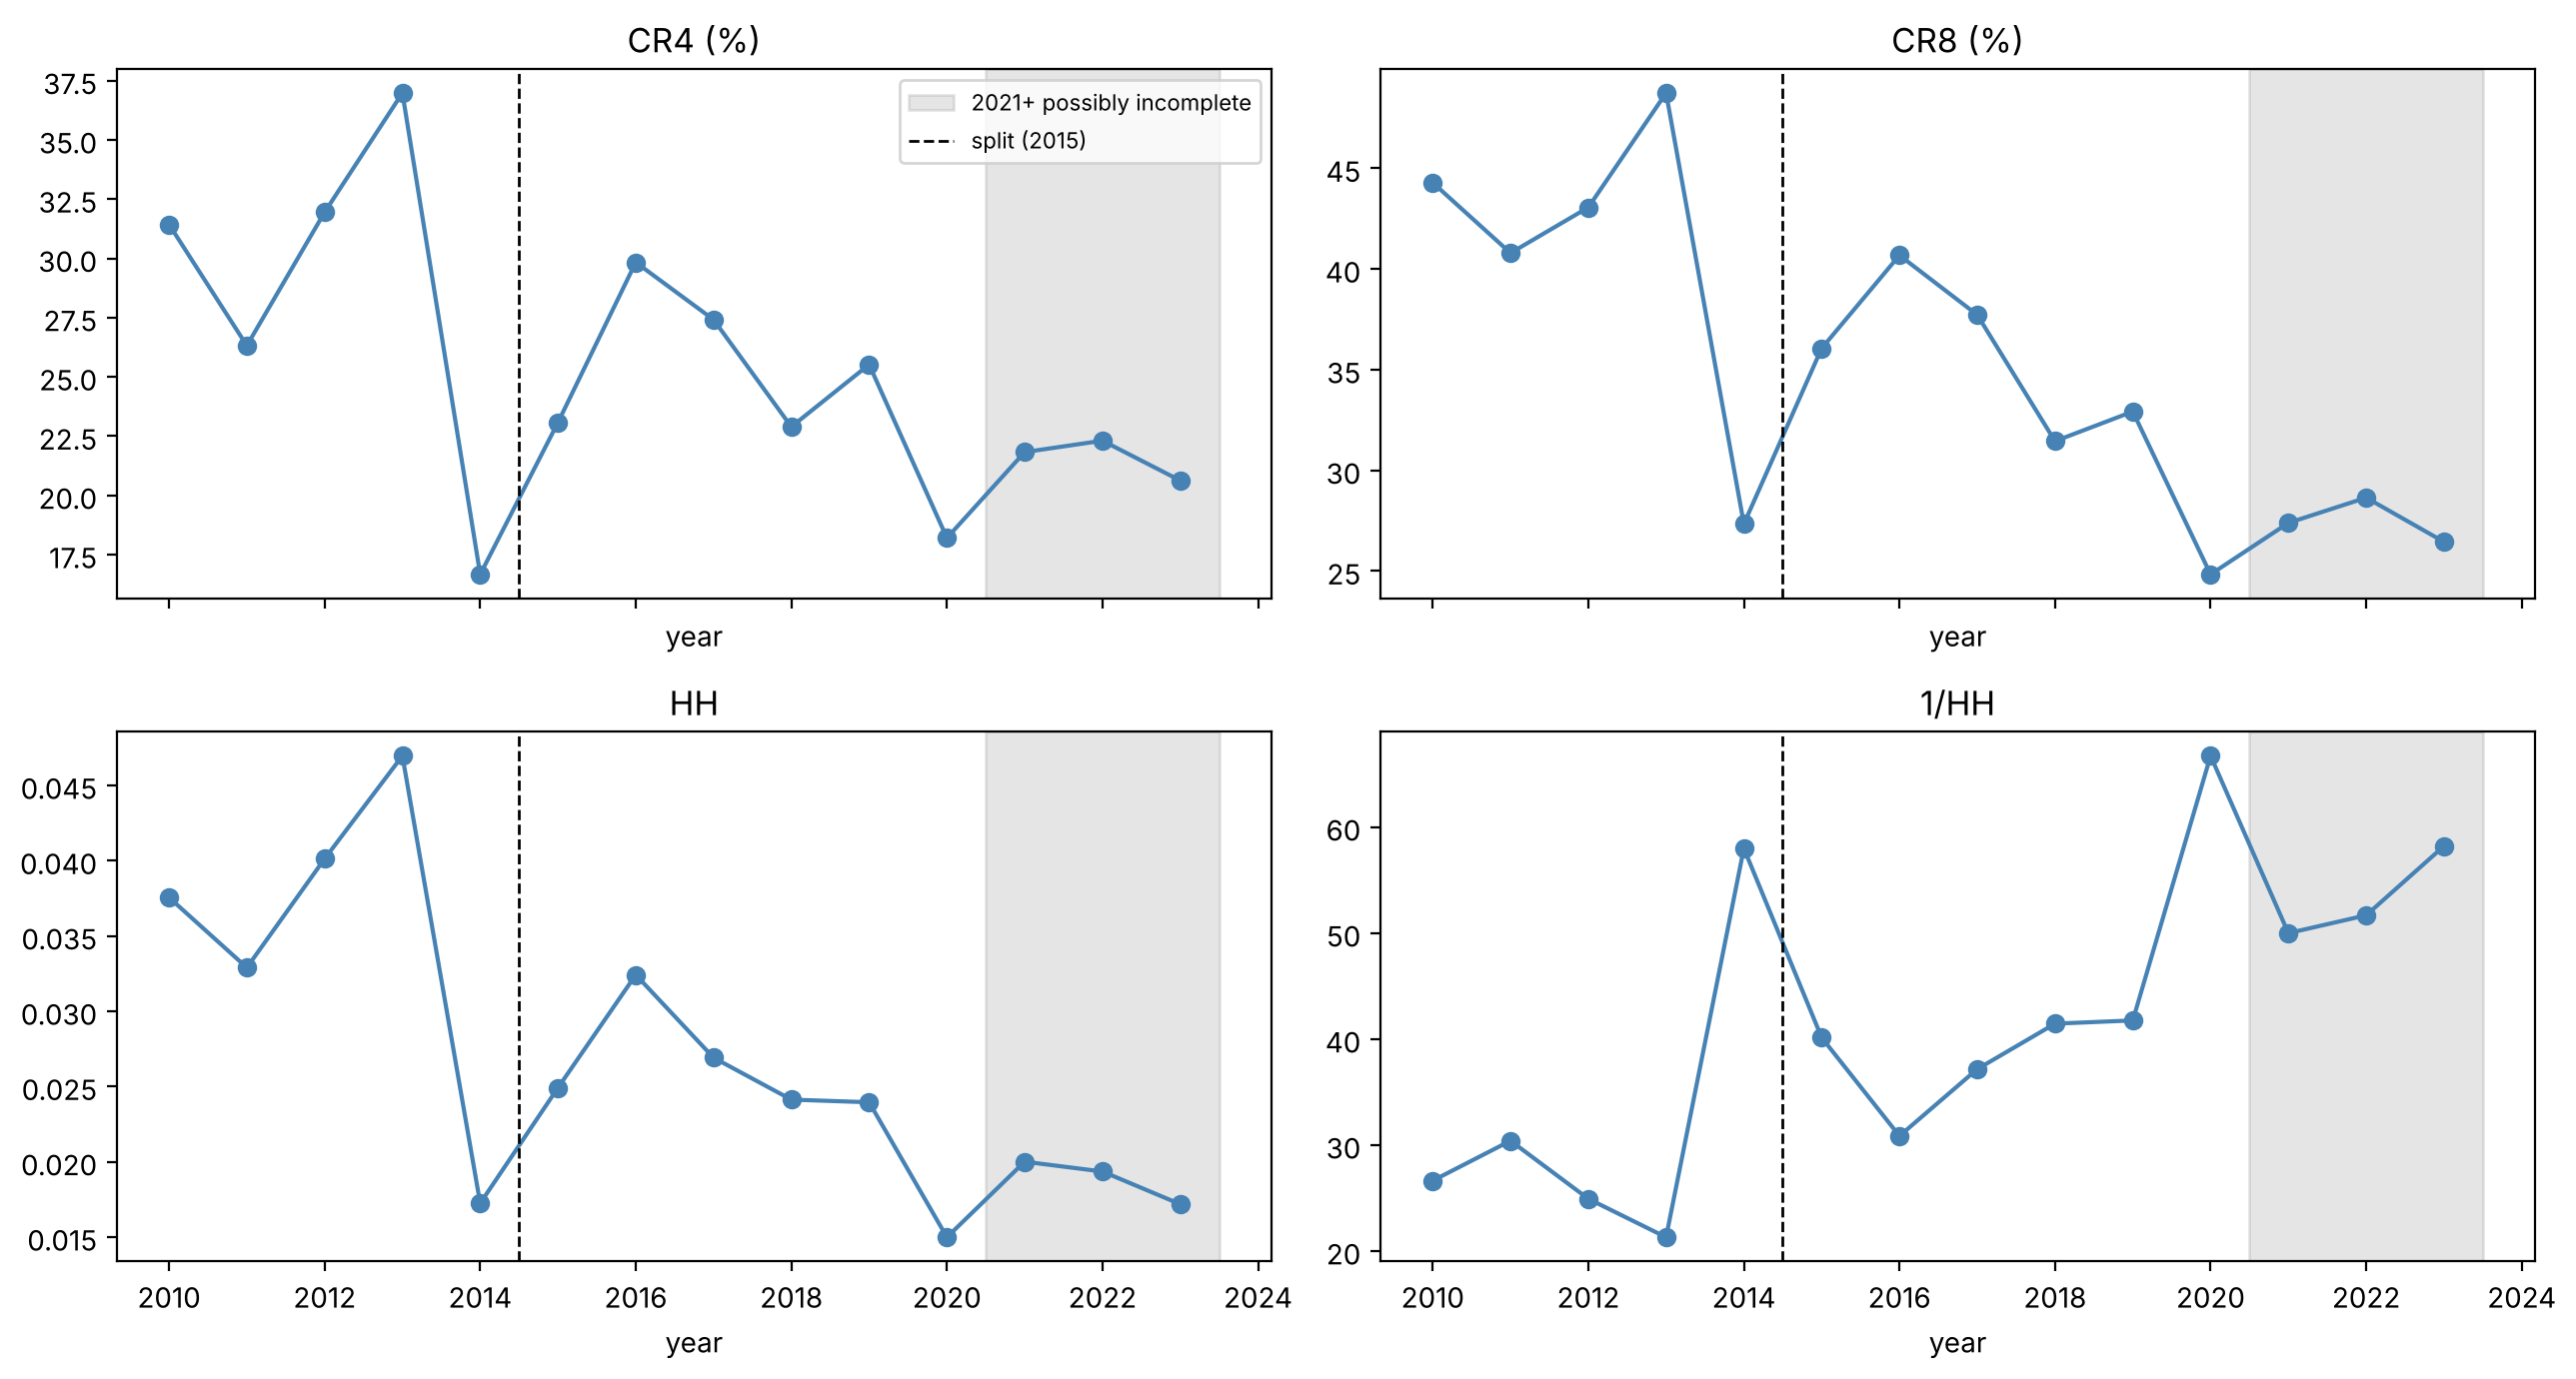

In [11]:
by_year = pd.DataFrame({y: six_measures(g.groupby("actor")["family"].nunique().to_numpy())
                        for y, g in links.groupby("year")}).T
by_year.insert(0, "families", links.groupby("year")["family"].nunique())
by_year.to_csv(OUTPUT_DIR / "concentration_by_year.csv")
display(by_year.rename(columns=ORG_LABELS)[["families", "organisations", "CR4 (%)", "CR8 (%)", "HH", "1/HH", "Gini"]].round(3).T)

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, col in zip(axes.flat, ["CR4 (%)", "CR8 (%)", "HH", "1/HH"]):
    ax.plot(by_year.index, by_year[col], marker="o", color="steelblue")
    shade(ax)
    ax.set(title=col, xlabel="year")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the yearly values.**

- **Small numbers before 2017.** Until 2016 there are 60–260 families and 46–134 actors a year, so one actor with ten families more or less moves CR4 by several points. The yearly values of these years jump and should not be read one by one.
- **The 2013 peak** (CR4 37%, HH 0.047) is one actor: D-Wave files 17 families out of 119 links (14%) and alone makes almost half of HH. In 2014 D-Wave falls to 6, no actor has more than 7 families, and 61 of the 92 actors are new (half of them universities, a third Chinese): CR4 drops to 17% and 1/HH jumps to 58. The 2014 "peak" of 1/HH is the end of the D-Wave year, not an event of the field.
- **From 2017 the years are comparable** (from 193 to 849 actors a year). The trend is clear: CR4 falls from 27% to 21%, HH from 0.027 to 0.017 and 1/HH rises from 37 to 58 equal actors, while Gini rises from 0.51 to 0.64. The top loses share while the tail of small actors grows. The single years still move by a few points (e.g. 2020).

To smooth the small early years, the same measures are computed on **windows of 3 years**, aligned on the split year so that the split and the grey years fall between two windows: 2010–11 (2 years), 2012–14, 2015–17, 2018–20 and 2021–23 (grey).

**Windows of 3 years**, aligned on the split year (the first one, 2010–11, has 2 years), and the eight largest actors of each window.

In [12]:
# window of each year: 3-year blocks starting from SPLIT_YEAR (the first one is cut at YEAR_MIN)
start = SPLIT_YEAR + (links["year"] - SPLIT_YEAR) // WINDOW * WINDOW
links["window"] = start.clip(lower=YEAR_MIN).astype(str) + "-" + (start + WINDOW - 1).clip(upper=YEAR_MAX).astype(str).str[2:]

by_window = pd.DataFrame({w: six_measures(g.groupby("actor")["family"].nunique().to_numpy())
                          for w, g in links.groupby("window")}).T
by_window.insert(0, "families", links.groupby("window")["family"].nunique())
by_window.to_csv(OUTPUT_DIR / "concentration_by_window.csv")
display(by_window.rename(columns=ORG_LABELS).round(3))

top8 = pd.DataFrame({w: [f"{a} ({n})" for a, n in g.groupby("actor")["family"].nunique().nlargest(8).items()]
                     for w, g in links.groupby("window")}, index=range(1, 9))
display(top8)

,families,organisations,families (sum over organisations),CV,CR4 (%),CR8 (%),HH,1/HH,Lotka L,Lotka p-value,Gini
2010-11,128,87.0,146.0,1.151,25.342,36.986,0.027,37.661,-1.575,0.001,0.356
2012-14,288,165.0,341.0,1.669,25.220,33.138,0.023,43.797,-1.347,0.000,0.447
2015-17,852,329.0,959.0,2.539,25.443,35.662,0.023,44.286,-1.140,0.000,0.578
2018-20,3141,885.0,3613.0,3.812,20.592,27.373,0.018,57.043,-1.128,0.000,0.661
2021-23,7130,1580.0,8101.0,5.220,21.220,26.577,0.018,55.961,-1.102,0.000,0.712


,2010-11,2012-14,2015-17,2018-20,2021-23
1,NTT (13),D-WAVE (29),IBM (78),IBM (364),ORIGIN QUANTUM (857)
2,NORTHROP GRUMMAN (10),MICROSOFT (26),INTEL (69),ORIGIN QUANTUM (152),IBM (399)
3,TOSHIBA (8),IBM (18),GOOGLE (ALPHABET) (60),RUBAN QUANTUM (143),BAIDU (307)
4,D-WAVE (6),NTT (13),MICROSOFT (37),MICROSOFT (85),FUJITSU (156)
5,XIAN UNIV TECH (6),NORTHROP GRUMMAN (8),RIGETTI (33),GOOGLE (ALPHABET) (83),QUANTINUUM (128)
6,FUJITSU (4),TOSHIBA (7),D-WAVE (26),INTEL (63),IONQ (119)
7,INTERNATIONAL SUPERCONDUCTIVITY TECH CENTER (4),GOOGLE (ALPHABET) (6),1QBIT (21),IONQ (51),GOOGLE (ALPHABET) (94)
8,HARVARD UNIV (3),UNITED STATES AMERICA AS REPRESENTED BY SECRET...,NORTHROP GRUMMAN (18),FUJITSU (48),MICROSOFT (93)


**Results by window.**

- **2010–11 and 2012–14: a small field.** 128 and 288 families. CR4 is about 25% and CR8 above 33%: a handful of actors is enough to hold a large share. The leaders are the pioneers of superconducting and annealing hardware: NTT, Northrop Grumman, Toshiba and D-Wave, then D-Wave and Microsoft (29 and 26 families in 2012–14), with IBM entering.
- **2015–17: the US tech firms take the lead.** Families triple (852). IBM (78), Intel (69), Google (60) and Microsoft (37) are the top 4, followed by start-ups such as Rigetti and 1QBit. CR4 stays at 25% because the leaders grow as fast as the field.
- **2018–20: China enters the head, the top loses share.** Families almost quadruple (3,141) and actors rise from 329 to 885. IBM grows to 364 families, Origin Quantum (152) and Ruban Quantum (143) enter the top 3, IonQ and Fujitsu the top 8. CR4 falls to 21%, CR8 to 27%, 1/HH rises from 44 to 57: the entrants are too many for any leader to keep its share.
- **2021–23 (grey): a new leader.** Origin Quantum (857) has twice the families of IBM (399); Baidu (307) and Fujitsu (156) complete the top 4, and Quantinuum and IonQ the top 8. CR4 and HH stay at the 2018–20 level.

**Who appears and who disappears.** The early pioneers do not disappear but stay small: D-Wave, NTT, Toshiba and Northrop Grumman file 10–55 families per window and fall out of the top 8 after 2017. Microsoft and Google grow slowly (about 90 families in 2021–23) and slide down the ranking. Intel peaks in 2015–17 and then halves (33 families in 2021–23), and Ruban Quantum almost stops filing after 2020 (10 families). The newcomers that climb are Chinese (Origin Quantum, Baidu; further down Tsinghua, Tencent, Alibaba), the Japanese Fujitsu and the pure-play quantum start-ups (IonQ, Quantinuum, IQM). The head of the field is therefore not stable: five of the eight largest actors of 2021–23 were not in the top 8 of 2015–17.

**Incumbents and entrants.** An actor is an *incumbent* if it has at least 2 families before the split year (2010–14); all the other actors active from 2015 are *entrants*. For the period after the split: the weight of the two groups, the 10 largest actors and the six measures in each group.

,actors,families with at least one,links,share of links (%)
group,,,,
incumbent,56,2757,2791,22.0
entrant,2087,8641,9882,78.0


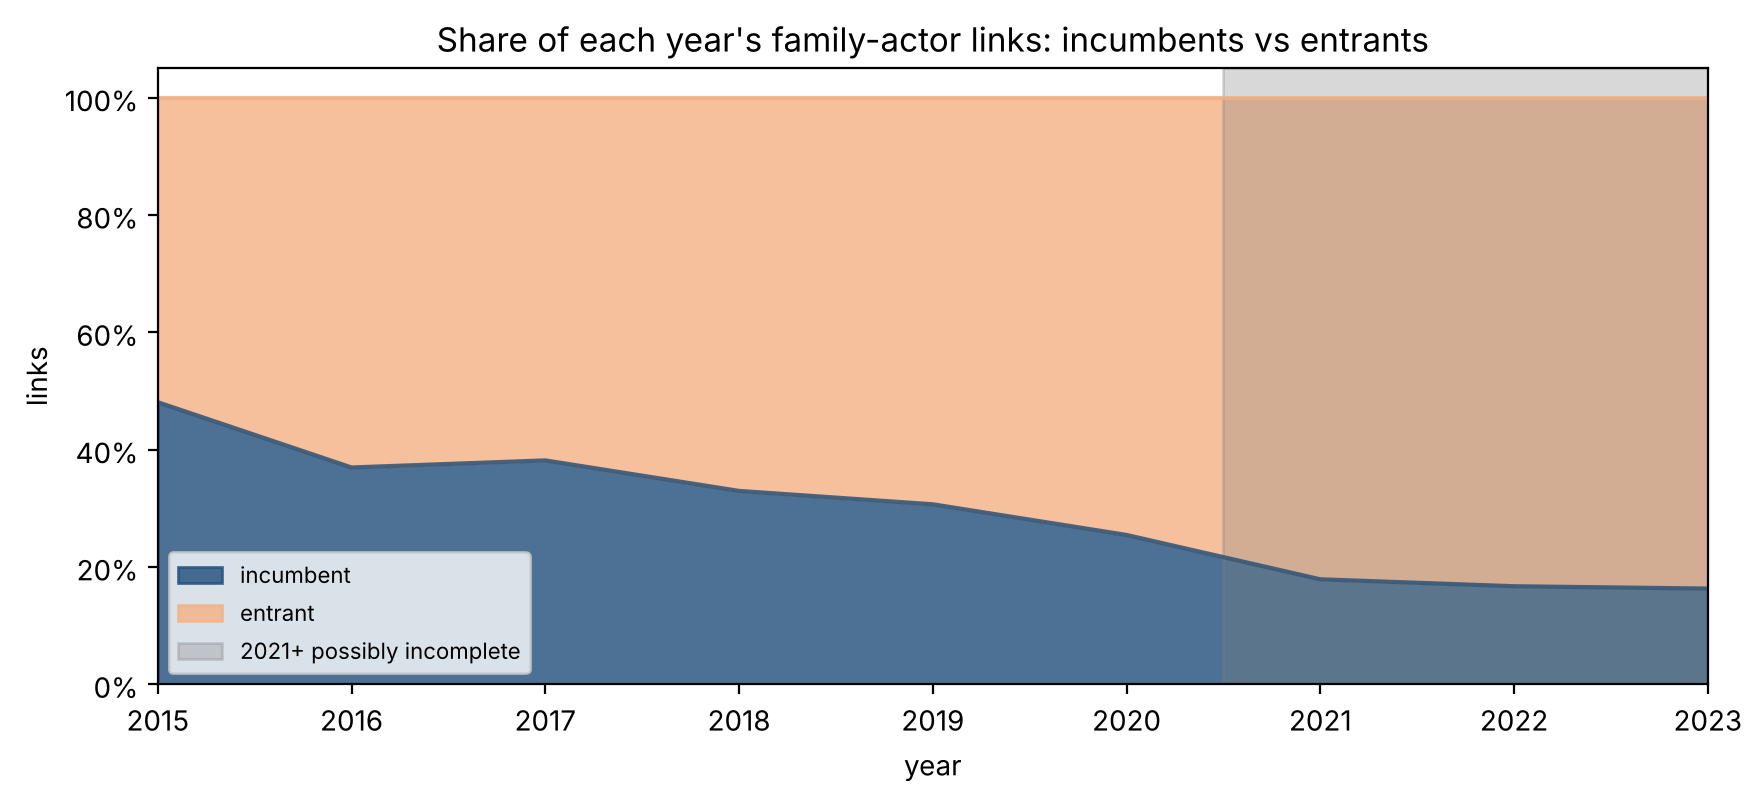

,group,country,families 2010-2014,families 2015-2023
actor,,,,
ORIGIN QUANTUM,entrant,CN,0,1010
IBM,incumbent,US,19,841
BAIDU,entrant,CN,0,354
GOOGLE (ALPHABET),incumbent,US,6,237
MICROSOFT,incumbent,US,28,215
FUJITSU,incumbent,JP,4,207
IONQ,entrant,US,0,173
INTEL,entrant,US,0,165
RUBAN QUANTUM,entrant,CN,0,153


,organisations,families (sum over organisations),CV,CR4 (%),CR8 (%),HH,1/HH,Lotka L,Lotka p-value,Gini
incumbent,56.0,2791.0,2.405,53.744,67.180,0.119,8.384,-0.238,0.0,0.733
entrant,2087.0,9882.0,5.419,17.223,22.222,0.015,68.773,-1.182,0.0,0.696


In [13]:
# ---- Incumbents and entrants ----
MIN_FAMILIES = 2      # incumbent: at least 2 families in YEAR_MIN..SPLIT_YEAR-1; all the others are entrants

before = links[links["year"] < SPLIT_YEAR].groupby("actor")["family"].nunique()
actors["group"] = np.where(actors.index.isin(before[before >= MIN_FAMILIES].index), "incumbent", "entrant")
GROUPS = ["incumbent", "entrant"]

after = links[links["year"] >= SPLIT_YEAR].join(actors["group"], on="actor")
families_after = after.groupby("actor")["family"].nunique()

# 1. weight of the two groups after the split
weight = pd.DataFrame({
    "actors": after.groupby("group")["actor"].nunique(),
    "families with at least one": after.groupby("group")["family"].nunique(),
    "links": after.groupby("group").size(),
}).reindex(GROUPS)
weight["share of links (%)"] = weight["links"] / weight["links"].sum() * 100
display(weight.round(1))

share_year = after.groupby(["year", "group"]).size().unstack()[GROUPS]
share_year = share_year.div(share_year.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 4))
share_year.plot.area(ax=ax, alpha=0.8, color=["#1f4e79", "#f4b183"])
ax.axvspan(GREY_FROM - 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.3, label=f"{GREY_FROM}+ possibly incomplete")
ax.set(title="Share of each year's family-actor links: incumbents vs entrants", xlabel="year", ylabel="links",
       xlim=(SPLIT_YEAR, YEAR_MAX))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(fontsize=8, loc="lower left")
plt.show()

# 2. who leads: the 10 largest actors after the split
top10 = actors.loc[families_after.nlargest(10).index, ["group", "country"]]
top10[f"families {YEAR_MIN}-{SPLIT_YEAR - 1}"] = before.reindex(top10.index).fillna(0).astype(int)
top10[f"families {SPLIT_YEAR}-{YEAR_MAX}"] = families_after.nlargest(10)
display(top10)

# 3. internal structure: the six measures in each group, after the split
by_group = pd.DataFrame({g: six_measures(families_after[actors.loc[families_after.index, "group"] == g].to_numpy())
                         for g in GROUPS}).T
display(by_group.rename(columns=ORG_LABELS).round(3))

**Results: incumbents and entrants.** Incumbents are the 56 organisations with at least 2 families in 2010–14; all the others active from 2015 are entrants (2,087).

- **Plot: growth is driven by entrants.** Incumbents hold 48% of the family-actor links in 2015, 25% in 2020 and 16% in 2023. Their share falls in every year, also before the grey band: the field grows mainly through organisations that were not patenting before 2015. Over 2015–23 entrants hold 78% of the links.
- **Top 10: the head is split.** Four leaders are incumbents (IBM, Google, Microsoft, Fujitsu) and six are entrants with no family before 2015 (Origin Quantum, Baidu, IonQ, Intel, Ruban Quantum, Quantinuum). The incumbents in the head are not old leaders that kept their position but early players that scaled up: IBM goes from 19 families in 2010–14 to 841, Fujitsu from 4 to 207. The entrants are of two kinds: quantum start-ups (Origin Quantum, IonQ, Quantinuum, Ruban) and large tech firms new to the field (Baidu, Intel). The largest actor of the whole period, Origin Quantum, is an entrant.
- **Six measures: two different structures.** Incumbents are a small, concentrated club: the top 4 hold 54% of their links, they behave like 8 equal actors (1/HH), and Lotka's L (−0.24) is close to 0, i.e. many large actors and few small ones. IBM alone holds 30% of their links. Entrants are many and fragmented: CR4 17%, 69 equal actors, Lotka's L (−1.18) closer to the usual shape. Their CV (5.4) is higher than that of incumbents (2.4) because a few very large entrants (Origin Quantum, Baidu) stand out from a long tail of actors with one or two families. Gini is similar (0.73 and 0.70): both groups are unequal, but for different reasons.

## 4. Geography

Country of the actor (Section 0.3); a family counts once per country of its actors. The 10 countries with most families are compared, the rest is grouped in *Others*.

,families,share (%)
area,,
CN,4624,40.1
US,3712,32.2
JP,899,7.8
KR,443,3.8
DE,345,3.0
CA,335,2.9
FR,249,2.2
GB,229,2.0
IL,125,1.1


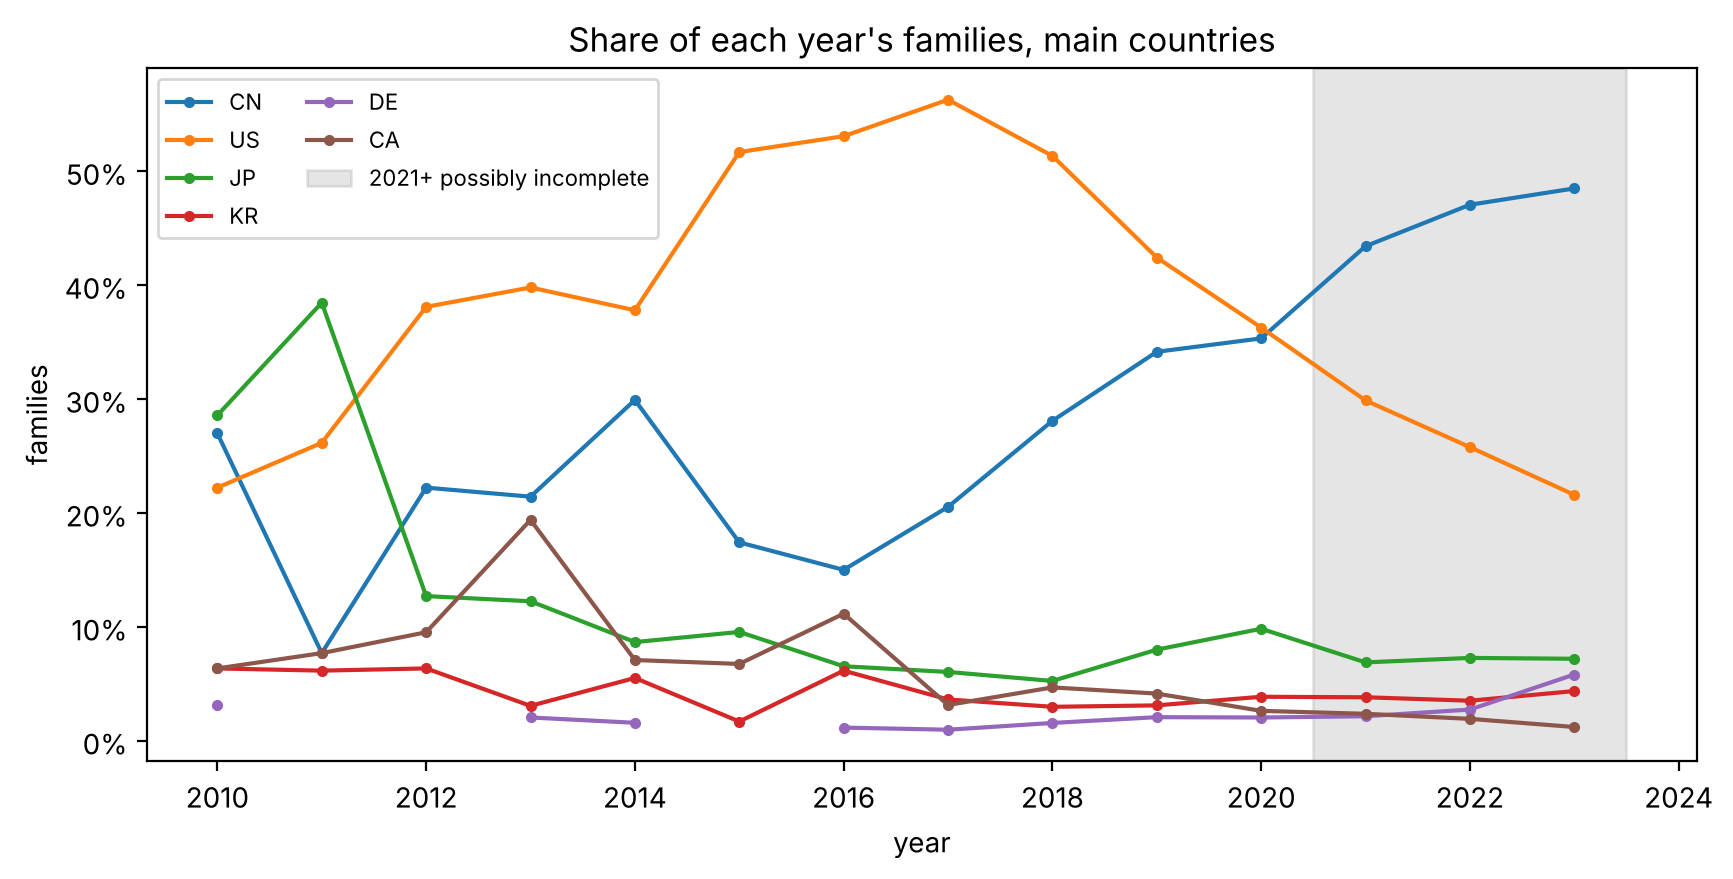

In [14]:
fam_country = links.drop_duplicates(["family", "country"])
main = fam_country["country"].value_counts().head(N_COUNTRIES).index        # the countries compared below
links["area"] = links["country"].where(links["country"].isin(main), "Others")
fam_area = links.drop_duplicates(["family", "area"])

by_country = fam_area["area"].value_counts().reindex([*main, "Others"]).rename("families").to_frame()
by_country["share (%)"] = by_country["families"] / links["family"].nunique() * 100
display(by_country.round(1))

share = (fam_area.groupby(["year", "area"])["family"].nunique().unstack()
         .div(links.groupby("year")["family"].nunique(), axis=0) * 100)
fig, ax = plt.subplots(figsize=(10, 4.5))
share[main[:6]].plot(ax=ax, marker="o", ms=3)
shade(ax, split=False)
ax.set(title="Share of each year's families, main countries", xlabel="year", ylabel="families")
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.legend(fontsize=8, ncol=2)
plt.show()

**Results.** China (40%) and the USA (32%) hold almost three families in four, followed by Japan (8%); no other country reaches 4%. The 10 countries cover 94% of the families (*Others* 6%).

### 4.1 Is the field concentrating geographically?

The same measures with **countries** as units instead of actors: CR2 (share of the two largest countries) and HH across countries, for each window.

In [15]:
GEO_FROM = 2013
fam_window_country = (links[links["year"] >= GEO_FROM].drop_duplicates(["family", "country"]).dropna(subset=["country"])
                      .assign(window=lambda d: d["window"].where(~d["window"].str.startswith("2012"), f"{GEO_FROM}-14")))
geo = pd.DataFrame({w: {"countries": g["country"].nunique(),
                        "CR2 (%)": concentration_ratio(g.groupby("country")["family"].nunique().to_numpy(), 2),
                        "HH": herfindahl(g.groupby("country")["family"].nunique().to_numpy()),
                        "first country": g["country"].value_counts().index[0],
                        "its share (%)": g["country"].value_counts(normalize=True).iloc[0] * 100}
                    for w, g in fam_window_country.groupby("window")}).T
display(geo.style.format({"countries": "{:.0f}", "CR2 (%)": "{:.1f}", "HH": "{:.3f}", "its share (%)": "{:.1f}"}))

,countries,CR2 (%),HH,first country,its share (%)
2013-14,18,61.1,0.220,US,36.4
2015-17,28,70.7,0.324,US,53.0
2018-20,33,73.6,0.284,US,40.9
2021-23,38,70.5,0.281,CN,45.8


**Results.** More and more countries patent (from 18 in 2013–14 to 38 in 2021–23), but the field becomes a **US–China duopoly**: CR2 rises from 61% to 71% and stays there, HH from 0.22 to 0.28. The leadership changes hands: the USA leads up to 2018–20 (53% of the families in 2015–17), China takes over in 2021–23 (46%, with the USA at 25%).

### 4.2 Country profiles

For each country: who patents (share of families with a company, a university, a public body), its largest actor and the concentration among its organisations.

In [16]:
def profile(g):
    per_actor = g.groupby("actor")["family"].nunique().sort_values(ascending=False)
    families = g["family"].nunique()
    row = {"families": families, "organisations": len(per_actor)}
    for t in TYPES:
        row[f"% with {t}"] = g.loc[g["type"] == t, "family"].nunique() / families * 100
    row["leader"] = per_actor.index[0]
    row["leader share (%)"] = per_actor.iloc[0] / per_actor.sum() * 100
    row["CR4 (%)"] = concentration_ratio(per_actor.to_numpy(), 4)
    row["1/HH"] = 1 / herfindahl(per_actor.to_numpy())
    return pd.Series(row)


profiles = pd.DataFrame({c: profile(links[links["country"] == c]) for c in main[:5]}).T
display(profiles.style.format("{:.1f}", subset=profiles.columns.drop(["families", "organisations", "leader"]))
        .format("{:,.0f}", subset=["families", "organisations"]))

,families,organisations,% with company,% with university,% with gov / non-profit,leader,leader share (%),CR4 (%),1/HH
CN,"4,624",936,64.1,33.6,5.3,ORIGIN QUANTUM,20.2,32.3,19.9
US,"3,712",441,84.9,15.6,2.0,IBM,21.3,37.7,16.2
JP,899,127,87.4,15.7,9.0,FUJITSU,20.0,47.1,13.3
KR,443,77,33.0,48.8,23.7,ETRI,14.1,42.8,15.7
DE,345,116,68.1,22.6,21.2,KIPU QUANTUM,6.3,22.2,38.3


**Results.** The five countries follow three different models:

- **Company-led with a clear leader: USA and Japan.** Companies are on 85–87% of the families. IBM holds 21% of the US links and Fujitsu 20% of the Japanese ones. Japan is the most concentrated of the five (CR4 47%, 13 equal actors), with Fujitsu, NTT, NEC and Toshiba.
- **Mixed: China.** Universities are on a third of the families (Tsinghua, USTC, Chinese Academy of Sciences), much more than in the USA (16%). Origin Quantum leads with 20%. China has by far the most organisations (936, twice the USA), but its CR4 (32%) is close to the US one (38%), because a few companies (Origin Quantum, Baidu, Ruban) hold a large share.
- **Public and academic: South Korea and Germany.** In Korea universities are on half of the families and public bodies on a quarter; the leader is a public research institute (ETRI, 14%). Germany has a large public share too (21%, e.g. Fraunhofer, Jülich), but it is the most fragmented of the five: the leader, the start-up Kipu Quantum, holds 6%, CR4 is 22% and the field behaves like 38 equal actors.

### 4.3 USA and China over time

CR4 and 1/HH among the organisations of each of the two largest countries, by window.

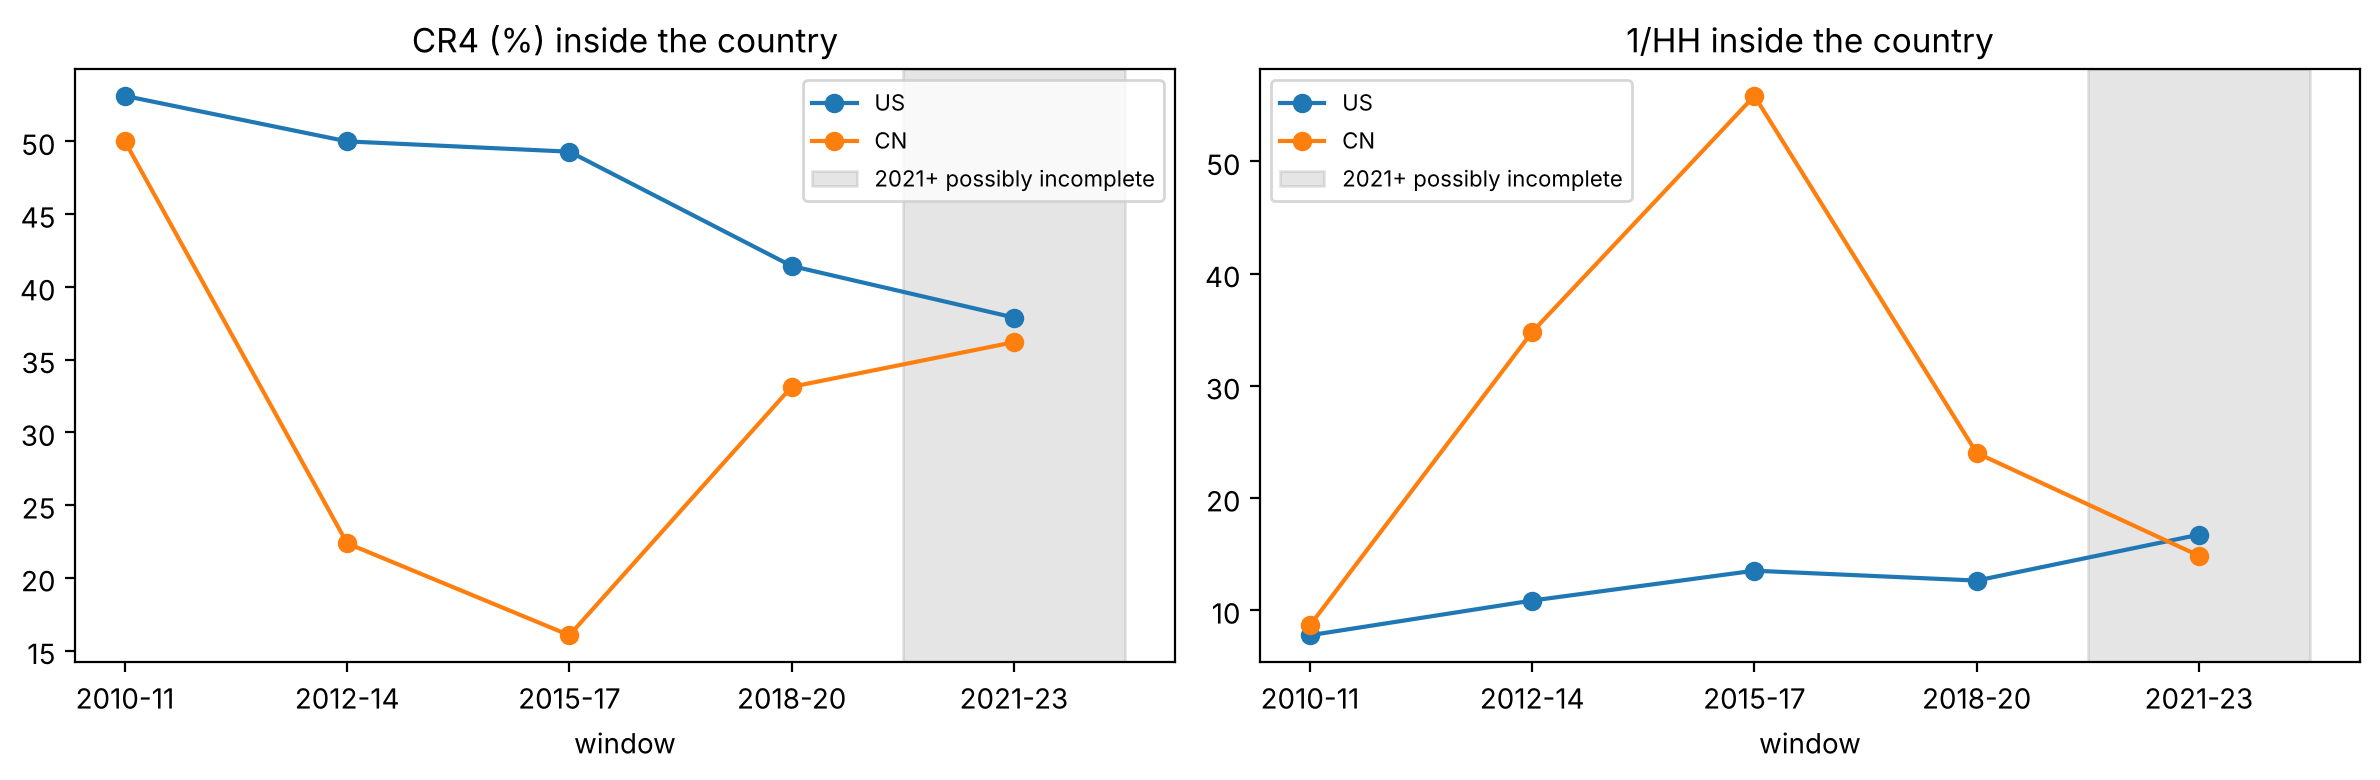

In [17]:
TWO = ["US", "CN"]
paths = pd.DataFrame({(c, w): {"families": g["family"].nunique(),
                               "organisations": g["actor"].nunique(),
                               "CR4 (%)": concentration_ratio(g.groupby("actor")["family"].nunique().to_numpy(), 4),
                               "1/HH": 1 / herfindahl(g.groupby("actor")["family"].nunique().to_numpy()),
                               "leader": g.groupby("actor")["family"].nunique().idxmax()}
                      for c in TWO for w, g in links[links["country"] == c].groupby("window")}).T
display(paths.style.format({"families": "{:,.0f}", "organisations": "{:,.0f}", "CR4 (%)": "{:.1f}", "1/HH": "{:.1f}"}))

windows = paths.loc[TWO[0]].index
pos = np.arange(len(windows))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["CR4 (%)", "1/HH"]):
    for c in TWO:
        ax.plot(pos, paths.loc[c, col].astype(float), marker="o", label=c)
    ax.axvspan(np.argmax(windows.str[:4].astype(int) >= GREY_FROM) - 0.5, len(pos) - 0.5, color="grey", alpha=0.2,
               label=f"{GREY_FROM}+ possibly incomplete")
    ax.set(title=f"{col} inside the country", xticks=pos, xticklabels=windows, xlabel="window")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Results.** The two countries move in **opposite directions**. In the USA CR4 falls from about 50% to 38% (1/HH from 8 to 17): IBM stays the leader, but many start-ups enter next to it. China does the reverse: in 2015–17 its patenting is spread over many universities (CR4 16%, 56 equal actors), then Origin Quantum and Baidu take the lead and CR4 rises to 36% (15 equal actors) in 2021–23. The two countries end the period at a similar level of concentration.

## Summary

- **Who patents.** Companies are on 71% of the families, universities on 24%; co-ownership between types is rare (5%). Individuals fade after 2012 and are left out of the measures.
- **How concentrated.** CR4 19%, 1/HH 71, Gini 0.74, Lotka L −1.07: the field is not dominated by a few actors, but it is very unequal, with a heavy head of large patentees and a long tail of actors with one or two families.
- **Consolidating?** No. Across the windows CR4 falls from about 25% to 21% and 1/HH rises, while inequality grows (Gini from 0.36 to 0.71). Entrants hold 78% of the links after 2015 and the head turns over: Origin Quantum, Baidu, IonQ and Quantinuum join IBM, Google, Microsoft and Fujitsu.
- **Where.** A US–China duopoly (CR2 about 71%), led by China from 2021. National models differ: company-led in the USA and Japan, mixed in China, public and academic in Korea and Germany. The USA de-concentrates around IBM, China re-concentrates around Origin Quantum and Baidu.